In [1]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Rectangle
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
%cd /Users/michelefilippucci/Data/ERA5/dictionaries/
!ls 
dic = np.load("ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1950-1960_DIC.npy",allow_pickle=True)

# Enable interactive mode in Jupyter notebook
#%matplotlib ipympl

/Users/michelefilippucci/Data/ERA5/dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_defaultfilt_daily_1943-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_defaultfilt_daily_1950-2021_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_defaultfilt_daily_1959-2021_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_defaultfilt_daily_jja_1943-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_defaultfilt_daily_jja_1950-2021_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_maxar8_daily_1943-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_maxar8_daily_1950-2021_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_maxar8_daily_jja_1950-2021_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_ml1000_daily_1950-1960_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1943-2023_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1950-1960_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1950-2021_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1959-2021_DIC.npy
ERA5_northem_2.5x2.5_zg_DAV_trac

In [3]:
dic = dic[1:]


#PERSISTENCE
pers = []
for event in dic:
  pers.append(event['persistence'])

#AREA
area = []
for event in dic:
  area.append(event['avg_area'])

#TRACK
track = []
for i,event in enumerate(dic):
  track.append(event['track'])

#ASPECT_RATIO
avg_aspect_ratio=[]
for event in dic:
  avg_aspect_ratio.append(event['avg_aspect_ratio'])

#MEAN DISTANCE TRAVELLED
dist = []
for event in dic:
  dist.append(event['distance_traveled'])



#COLOR
color = []
c = ''
for l,event in enumerate(dic):
  try:
    xs,ys = event['track']
  except:
    print(l)
  if np.mean(xs) >= 65:
    c = 'r'
  elif 45 <= np.mean(xs) < 65:
    c = 'g'
  elif np.mean(xs) < 45:
    c = 'lightskyblue'
  color.append(c)
'''

#COLOR
color = []
c = ''
threshold = 350
for event in dic:
  D = event['distance_traveled']
  if D>=threshold:
    c = 'red'
  elif D<threshold:
    c = 'blue'
  color.append(c)
'''

8035


"\n\n#COLOR\ncolor = []\nc = ''\nthreshold = 350\nfor event in dic:\n  D = event['distance_traveled']\n  if D>=threshold:\n    c = 'red'\n  elif D<threshold:\n    c = 'blue'\n  color.append(c)\n"

In [4]:
dic[0]

{'persistence': 7,
 'avg_area': 1207468.415584302,
 'avg_aspect_ratio': 1.6760698371764897,
 'distance_traveled': 2837.853542266376,
 'track': ([44.0,
   44.16666666666667,
   41.66666666666667,
   41.75,
   44.573170731707314,
   46.84782608695652,
   46.25],
  [-142.66666666666666,
   -141.16666666666666,
   -146.52777777777777,
   -156.25,
   -160.7317073170732,
   -160.65217391304347,
   -165.0]),
 'date': numpy.datetime64('1950-01-01T06:00:00.000000000'),
 'time': 0}

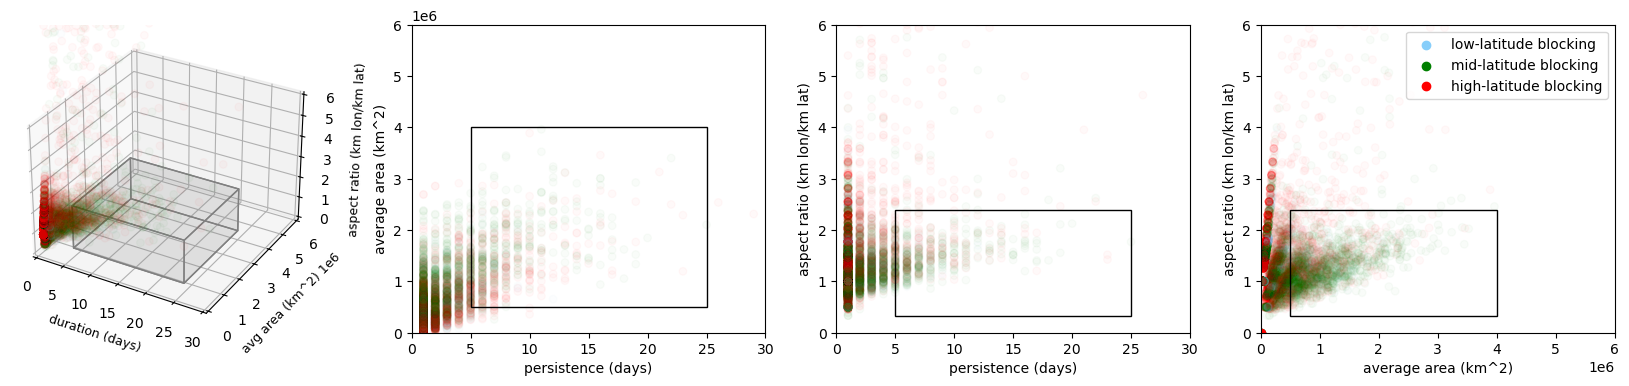

8036


In [6]:
fig = plt.figure(figsize=(21,4))

size=30
alpha=0.025
alpha_cube = 0.1
alpha_square=1
face_color = 'grey'

#3D scatter plot
ax = fig.add_subplot(141, projection='3d')
ax.scatter(pers, np.array(area)/1e6, avg_aspect_ratio,alpha=alpha,c = color,s=size)
ax.set_xlabel('duration (days)',fontsize=9)
ax.set_ylabel('avg area (km^2) 1e6',loc='top',fontsize=9)
ax.set_zlabel('aspect ratio (km lon/km lat)',fontsize=9)
ax.set_xlim(0, 30)  # Set x-axis range
ax.set_ylim(0, 6)  # Set y-axis range
ax.set_zlim(0, 6)  # Set z-axis range
# Define cube vertices
min_pers = 5
max_pers = 25 #np.amax(pers)
min_area = 500000/1e6
max_area = 4e6/1e6#np.amax(area)
min_ext = np.amin(avg_aspect_ratio)
max_ext = 2.4
cube_vertices = [
    [min_pers, min_area, min_ext],
    [max_pers, min_area, min_ext],
    [max_pers, max_area, min_ext],
    [min_pers, max_area, min_ext],
    [min_pers, min_area, max_ext],
    [max_pers, min_area, max_ext],
    [max_pers, max_area, max_ext],
    [min_pers, max_area, max_ext],
]
cube_faces = [
    [cube_vertices[0], cube_vertices[1], cube_vertices[2], cube_vertices[3]],
    [cube_vertices[4], cube_vertices[5], cube_vertices[6], cube_vertices[7]],
    [cube_vertices[0], cube_vertices[1], cube_vertices[5], cube_vertices[4]],
    [cube_vertices[2], cube_vertices[3], cube_vertices[7], cube_vertices[6]],
    [cube_vertices[0], cube_vertices[3], cube_vertices[7], cube_vertices[4]],
    [cube_vertices[1], cube_vertices[2], cube_vertices[6], cube_vertices[5]],
]
cube = Poly3DCollection(cube_faces, alpha=alpha_cube, facecolors=face_color, edgecolors='grey')
ax.add_collection3d(cube)
#ax.set_title('a')

min_area = min_area*1e6
max_area = max_area*1e6#np.amax(area)

#XY projection
ax2d = fig.add_subplot(142)
ax2d.scatter(pers,area,alpha=alpha,c = color,s=size)
ax2d.set_xlim(0, 30)
ax2d.set_ylim(0, 6e6)
square = Rectangle((min_pers, min_area), max_pers-min_pers, max_area-min_area, alpha=alpha_square, edgecolor='black', fill = False)
ax2d.add_patch(square)
ax2d.set_xlabel('persistence (days)')
ax2d.set_ylabel('average area (km^2)')
#ax2d.set_title('b')

#XZ projection
ax2d = fig.add_subplot(143)
ax2d.scatter(pers,avg_aspect_ratio,alpha=alpha,c = color,s=size)
ax2d.set_xlim(0, 30)
ax2d.set_ylim(0, 6)
square = Rectangle((min_pers, min_ext), max_pers-min_pers, max_ext-min_ext, alpha=alpha_square, edgecolor='black', fill = False)
ax2d.add_patch(square)
ax2d.set_xlabel('persistence (days)')
ax2d.set_ylabel('aspect ratio (km lon/km lat)')
#ax2d.set_title('c')


#YZ projection
ax2d = fig.add_subplot(144)
ax2d.scatter(area,avg_aspect_ratio,alpha=alpha,c = color,s=size)
#FAKE SCATTER PLOT TO SET THE LABELS
ax2d.scatter(0,0,c='lightskyblue',label='low-latitude blocking')
ax2d.scatter(0,0,c='green',label='mid-latitude blocking')
ax2d.scatter(0,0,c='red',label='high-latitude blocking')
ax2d.set_xlim(0, 6e6)
ax2d.set_ylim(0, 6)
square = Rectangle((min_area, min_ext), max_area-min_area, max_ext-min_ext, alpha=alpha_square, edgecolor='black', fill = False)
ax2d.add_patch(square)
ax2d.set_xlabel('average area (km^2)')
ax2d.set_ylabel('aspect ratio (km lon/km lat)')
#ax2d.set_title('d')
ax2d.legend()


# Show the plot
#plt.savefig("/Users/michelefilippucci/Pictures/PLOTS/scatter.png",bbox_inches='tight',dpi = 400)
plt.show()
print(len(color))

#### Sarebbe interessante vedere se il longitudinal avg_aspect_ratio ha una dipendenza dalla latitudine.


inoltre sarebbe meglio usare delle 2d heatmaps invece degli scatter plots quando si passa in 2d

In [ ]:

fig = plt.figure(figsize=(22,4))


size=0.1

#3D scatter plot
ax = fig.add_subplot(141, projection='3d')
ax.scatter(pers, area, avg_aspect_ratio,c = color,s=size)
ax.set_xlabel('persistence')
ax.set_ylabel('avg area')
ax.set_zlabel('aspect_ratio')
ax.set_xlim(0, 25)  # Set x-axis range
ax.set_ylim(0, 7e6)  # Set y-axis range
ax.set_zlim(0, 100)  # Set z-axis range
# Define cube vertices
min_pers = 4
max_pers = 20 #np.amax(pers)
min_area = 500000
max_area = 5e6 #np.amax(area)
min_ext = np.amin(avg_aspect_ratio)
max_ext = 60
cube_vertices = [
    [min_pers, min_area, min_ext],
    [max_pers, min_area, min_ext],
    [max_pers, max_area, min_ext],
    [min_pers, max_area, min_ext],
    [min_pers, min_area, max_ext],
    [max_pers, min_area, max_ext],
    [max_pers, max_area, max_ext],
    [min_pers, max_area, max_ext],
]
cube_faces = [
    [cube_vertices[0], cube_vertices[1], cube_vertices[2], cube_vertices[3]],
    [cube_vertices[4], cube_vertices[5], cube_vertices[6], cube_vertices[7]],
    [cube_vertices[0], cube_vertices[1], cube_vertices[5], cube_vertices[4]],
    [cube_vertices[2], cube_vertices[3], cube_vertices[7], cube_vertices[6]],
    [cube_vertices[0], cube_vertices[3], cube_vertices[7], cube_vertices[4]],
    [cube_vertices[1], cube_vertices[2], cube_vertices[6], cube_vertices[5]],
]
cube = Poly3DCollection(cube_faces, alpha=0.25, facecolors='cyan', edgecolors='grey')
ax.add_collection3d(cube)

x = pers
y = area
zlim = 100
range = [[0,20],[0,6e6]]
xlabel = 'persistence'
ylabel = 'avg area'
ax = hist3d(x,y,zlim,range,xlabel,ylabel,sbplt_code=142,bins=(15,30))

x = pers
y = avg_aspect_ratio
zlim = 100
range = [[0,20],[0,60]]
xlabel = 'persistence'
ylabel = 'aspect_ratio'
ax = hist3d(x,y,zlim,range,xlabel,ylabel,sbplt_code=143,bins=(15,30))

x = area
y = avg_aspect_ratio
zlim = 100
range = [[0,6e6],[0,60]]
xlabel = 'area'
ylabel = 'aspect_ratio'
ax = hist3d(x,y,zlim,range,xlabel,ylabel,sbplt_code=144,bins=(15,30))


plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

# Enable interactive mode in Jupyter notebook
%matplotlib ipympl

x = pers
y = area
zlim = 100
range = [[0,20],[0,6e6]]
xlabel = 'persistence'
ylabel = 'avg area'

def hist3d(x,y,zlim,range,xlabel,ylabel):
  ax = fig.add_subplot(111, projection='3d')
  hist, xedges, yedges = np.histogram2d(x, y, bins=(15, 30),range=range)
  xpos, ypos = np.meshgrid(xedges[:-1] + 0.25, yedges[:-1] + 0.25, indexing="ij")
  xpos = xpos.ravel()
  ypos = ypos.ravel()
  zpos = np.zeros_like(xpos)
  dx = dy = 0.5
  dz = hist.ravel()
  dz = np.where(dz>zlim,zlim,dz)
  ax.plot_trisurf(xpos, ypos, dz, vmin=0, vmax=100,cmap='viridis')
  # Add labels and title
  ax.set_xlabel('persistence')
  ax.set_ylabel('avg area')
  ax.set_zlabel('Frequency')
  ax.set_zlim(0,zlim)
  return ax

fig = plt.figure(figsize=(6,4))
ax = hist3d(x,y,zlim,range,xlabel,ylabel)
plt.show()
